[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/calculus-and-optimization/integrals/notebook.ipynb)

# Integrals: hands-on

This notebook goes with the [topic README](README.md). You will draw Riemann rectangles and watch their sums converge, see the area function and its derivative match the curve, compare exact and numerical integrals, shade an area between curves, draw an average value as a rectangle, build a disc volume, check substitution and integration by parts with SymPy, watch improper integrals converge or diverge, approach the Gaussian integral, measure the errors of the midpoint, trapezoid, and Simpson rules, and then meet integrals in AI: a density with its CDF and expected value, softplus as an antiderivative of the sigmoid, Monte Carlo integration, and the area under an ROC curve. All data are invented or computed on the spot. It uses NumPy, SymPy, SciPy, and Matplotlib, and runs in a few seconds on a CPU.

Numerical checks hold only up to rounding error, so we compare floats with `np.isclose` and `np.allclose`, never with `==`.

In [1]:
%matplotlib inline
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.integrate import quad, trapezoid, cumulative_trapezoid
from scipy.special import erf

plt.rcParams["figure.dpi"] = 46
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
np.set_printoptions(precision=6, suppress=True)
x, t = sp.symbols("x t", positive=True)   # SymPy symbols used in the symbolic cells

## 1. Riemann rectangles

The integral starts as a sum of thin rectangles. The function `riemann` below builds the left, right, or midpoint sum for $n$ strips. The picture shows $f(x)=x^2$ on $[0,1]$ with $n = 4, 16, 64$ midpoint rectangles, and the title of each panel shows the sum. The true area is $1/3$.

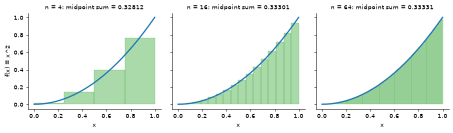

In [2]:
def riemann(f, a, b, n, rule="mid"):
    dx = (b - a) / n
    left = a + dx * np.arange(n)                      # left edge of each strip
    pts = {"left": left, "right": left + dx, "mid": left + dx / 2}[rule]
    return np.sum(f(pts)) * dx

f = lambda x: x**2
xs = np.linspace(0, 1, 300)
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, n in zip(axes, [4, 16, 64]):
    dx = 1 / n
    for i in range(n):
        ax.add_patch(Rectangle((i * dx, 0), dx, f(i * dx + dx / 2), fc="C2", alpha=0.4, ec="C2", lw=0.6))
    ax.plot(xs, f(xs), "C0", lw=2)
    ax.set_title(f"n = {n}: midpoint sum = {riemann(f, 0, 1, n):.5f}")
    ax.set_xlabel("x")
axes[0].set_ylabel("f(x) = x^2")
plt.tight_layout()
plt.show()

Now the table. Left sums sit below the true area and right sums above it (because $x^2$ is rising on $[0,1]$), the midpoint sum is closest, and all three close in on $1/3$ as $n$ grows.

In [3]:
print(f"{'n':>5} {'left':>9} {'right':>9} {'midpoint':>9} {'right-left':>11}")
for n in [4, 16, 64, 256, 1024]:
    L, R, M = (riemann(f, 0, 1, n, r) for r in ("left", "right", "mid"))
    print(f"{n:>5} {L:>9.5f} {R:>9.5f} {M:>9.5f} {R - L:>11.5f}")
print("exact:", 1 / 3, "| left below, right above:", riemann(f, 0, 1, 256, "left") < 1/3 < riemann(f, 0, 1, 256, "right"))

    n      left     right  midpoint  right-left
    4   0.21875   0.46875   0.32812     0.25000
   16   0.30273   0.36523   0.33301     0.06250
   64   0.32556   0.34119   0.33331     0.01562
  256   0.33138   0.33529   0.33333     0.00391
 1024   0.33285   0.33382   0.33333     0.00098
exact: 0.3333333333333333 | left below, right above: True


## 2. Exact integrals with SymPy, and the rules of the integral

By the fundamental theorem, $\int_a^b f = F(b) - F(a)$. SymPy finds antiderivatives (it leaves out the $+C$) and `quad` computes the same number numerically, so we can compare the two.

In [4]:
cases = [("x**2 on [0, 1]", x**2, 0, 1), ("sin(x) on [0, pi]", sp.sin(x), 0, sp.pi), ("exp(x) on [0, 1]", sp.exp(x), 0, 1),
         ("1/x on [1, e]", 1 / x, 1, sp.E), ("x*exp(x) on [0, 1]", x * sp.exp(x), 0, 1)]
for name, expr, a, b in cases:
    exact = sp.integrate(expr, (x, a, b))
    numeric = quad(sp.lambdify(x, expr, "numpy"), float(a), float(b))[0]
    print(f"{name:20} antiderivative {str(sp.integrate(expr, x)):22} exact {str(exact):10} numeric {numeric:.6f}  match {np.isclose(float(exact), numeric)}")

x**2 on [0, 1]       antiderivative x**3/3                 exact 1/3        numeric 0.333333  match True
sin(x) on [0, pi]    antiderivative -cos(x)                exact 2          numeric 2.000000  match True
exp(x) on [0, 1]     antiderivative exp(x)                 exact -1 + E     numeric 1.718282  match True
1/x on [1, e]        antiderivative log(x)                 exact 1          numeric 1.000000  match True
x*exp(x) on [0, 1]   antiderivative (x - 1)*exp(x)         exact 1          numeric 1.000000  match True


The properties from the README (linearity, splitting the interval, swapping limits, signed area) hold numerically too.

In [5]:
g = lambda x: np.cos(x) + 1
I = lambda func, a, b: quad(func, a, b)[0]
print("linearity   :", np.isclose(I(lambda x: 3 * f(x) + g(x), 0, 2), 3 * I(f, 0, 2) + I(g, 0, 2)))
print("splitting   :", np.isclose(I(f, 0, 3), I(f, 0, 1) + I(f, 1, 3)))
print("swap limits :", np.isclose(I(f, 2, 0), -I(f, 0, 2)))
print("signed area : integral of sin on [0, 2 pi] =", round(I(np.sin, 0, 2 * np.pi), 10),
      "| unsigned area =", round(I(lambda x: np.abs(np.sin(x)), 0, 2 * np.pi), 6))

linearity   : True
splitting   : True
swap limits : True
signed area : integral of sin on [0, 2 pi] = 0.0 | unsigned area = 4.0


## 3. The area function and the fundamental theorem

Define $A(x) = \int_0^x f(t)\,dt$ for $f(t) = 1 + \sin t$. Part 1 of the fundamental theorem says $A'(x) = f(x)$: the running total climbs at a rate equal to the height of the curve. We build $A$ numerically with a cumulative trapezoid sum, differentiate it with `np.gradient`, and compare with $f$. SymPy gives the exact formula, $A(x) = x - \cos x + 1$.

exact A(x): x - cos(x) + 1 | A(3) numeric: 4.98998 exact: 4.98999
A'(x) matches f(x) away from the ends: True


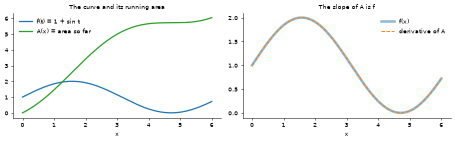

In [6]:
fc = lambda t: 1 + np.sin(t)
tt = np.linspace(0, 6, 601)
A = cumulative_trapezoid(fc(tt), tt, initial=0)       # running area from 0 to each point
dA = np.gradient(A, tt)                               # numerical derivative of the area
print("exact A(x):", sp.integrate(1 + sp.sin(t), (t, 0, x)), "| A(3) numeric:", round(A[300], 5), "exact:", round(3 - np.cos(3) + 1, 5))
print("A'(x) matches f(x) away from the ends:", np.allclose(dA[2:-2], fc(tt[2:-2]), atol=1e-3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
a1.plot(tt, fc(tt), "C0", lw=2, label="f(t) = 1 + sin t")
a1.plot(tt, A, "C2", lw=2, label="A(x) = area so far")
a1.set_xlabel("x"); a1.legend(frameon=False); a1.set_title("The curve and its running area")
a2.plot(tt, fc(tt), "C0", lw=4, alpha=0.5, label="f(x)")
a2.plot(tt, dA, "C1--", lw=1.5, label="derivative of A")
a2.set_xlabel("x"); a2.legend(frameon=False); a2.set_title("The slope of A is f")
plt.tight_layout(); plt.show()

## 4. Area between curves and average value

The line $y = x + 2$ and the parabola $y = x^2$ meet at $x = -1$ and $x = 2$. The area between them is the integral of (top minus bottom). On the right, the average value of $x^2$ on $[0, 3]$ is drawn as a flat rectangle with the same area as the region under the curve.

crossings: [-1, 2] | area between: 9/2 | average of x^2 on [0, 3]: 3


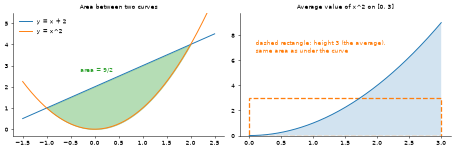

In [7]:
xr = sp.symbols("xr")
crossings = sp.solve(sp.Eq(xr**2, xr + 2), xr)
area = sp.integrate(xr + 2 - xr**2, (xr, crossings[0], crossings[1]))
avg = sp.integrate(xr**2, (xr, 0, 3)) / 3
print("crossings:", crossings, "| area between:", area, "| average of x^2 on [0, 3]:", avg)

fig, (b1, b2) = plt.subplots(1, 2, figsize=(10, 3.4))
xx = np.linspace(-1.5, 2.5, 300)
b1.plot(xx, xx + 2, label="y = x + 2"); b1.plot(xx, xx**2, label="y = x^2")
xm = np.linspace(-1, 2, 200)
b1.fill_between(xm, xm**2, xm + 2, color="C2", alpha=0.35)
b1.text(-0.3, 2.7, f"area = {area}", color="C2"); b1.set_ylim(-0.3, 5.5); b1.legend(frameon=False, loc="upper left")
b1.set_title("Area between two curves")
xa = np.linspace(0, 3, 200)
b2.plot(xa, xa**2); b2.fill_between(xa, 0, xa**2, alpha=0.2)
b2.add_patch(Rectangle((0, 0), 3, float(avg), fc="none", ec="C1", lw=2, ls="--"))
b2.text(0.1, 6.6, f"dashed rectangle: height {avg} (the average),\nsame area as under the curve", color="C1")
b2.set_ylim(0, 9.8); b2.set_title("Average value of x^2 on [0, 3]")
plt.tight_layout(); plt.show()

## 5. A disc volume

Spin the region under $y = \sqrt{x}$, $0 \le x \le 4$, around the $x$-axis. A slice at $x$ is a disc of radius $\sqrt{x}$ and volume about $\pi (\sqrt{x})^2\,dx$, so $V = \pi\int_0^4 x\,dx = 8\pi$. Below we add up many thin discs by machine and compare.

exact: 8*pi 25.132741228718345 | sum of discs: 25.132741228718345 | close: True


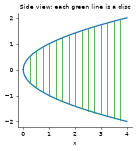

In [8]:
V_exact = sp.integrate(sp.pi * x, (x, 0, 4))
n = 2000
dx = 4 / n
mids = dx * (np.arange(n) + 0.5)
V_discs = np.sum(np.pi * np.sqrt(mids) ** 2 * dx)      # sum of disc volumes
print("exact:", V_exact, float(V_exact), "| sum of discs:", V_discs, "| close:", np.isclose(V_discs, float(V_exact)))

xs4 = np.linspace(0, 4, 300)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(xs4, np.sqrt(xs4), "C0", lw=2); ax.plot(xs4, -np.sqrt(xs4), "C0", lw=2)
for xi in np.linspace(0.25, 3.75, 15):
    ax.plot([xi, xi], [-np.sqrt(xi), np.sqrt(xi)], "C2", lw=1.2)
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_title("Side view: each green line is a disc")
plt.tight_layout(); plt.show()

## 6. Substitution and integration by parts, checked

An antiderivative is correct when its derivative returns the integrand, and SymPy can test that. Each pair below is the README example: first an antiderivative found by substitution or by parts, then the difference between its derivative and the integrand, which should simplify to $0$.

In [9]:
checks = {
    "2x cos(x^2)   [u = x^2]":  (2 * x * sp.cos(x**2), sp.sin(x**2)),
    "e^(3x)        [u = 3x]":   (sp.exp(3 * x), sp.exp(3 * x) / 3),
    "x e^x         [by parts]": (x * sp.exp(x), (x - 1) * sp.exp(x)),
    "ln x          [by parts]": (sp.log(x), x * sp.log(x) - x),
    "x cos x       [by parts]": (x * sp.cos(x), x * sp.sin(x) + sp.cos(x)),
}
for name, (integrand, F) in checks.items():
    print(f"{name:26} derivative minus integrand = {sp.simplify(sp.diff(F, x) - integrand)}")

print("\nWith limits: u = x^2 + 1 turns [0, 1] into [1, 2]")
print(sp.integrate(2 * x * (x**2 + 1)**3, (x, 0, 1)), "=", sp.integrate(sp.Symbol("u")**3, (sp.Symbol("u"), 1, 2)))
print("by parts, x e^x on [0, 1]:", sp.integrate(x * sp.exp(x), (x, 0, 1)), "| ln x on [1, e]:", sp.integrate(sp.log(x), (x, 1, sp.E)))
print("x/(x^2+1) on [0, 2]:", sp.integrate(x / (x**2 + 1), (x, 0, 2)), "=", sp.log(5) / 2, "=", float(sp.log(5) / 2))

2x cos(x^2)   [u = x^2]    derivative minus integrand = 0
e^(3x)        [u = 3x]     derivative minus integrand = 0
x e^x         [by parts]   derivative minus integrand = 0
ln x          [by parts]   derivative minus integrand = 0
x cos x       [by parts]   derivative minus integrand = 0

With limits: u = x^2 + 1 turns [0, 1] into [1, 2]
15/4 = 15/4
by parts, x e^x on [0, 1]: 1 | ln x on [1, e]: 1


x/(x^2+1) on [0, 2]: log(5)/2 = log(5)/2 = 0.8047189562170501


## 7. Improper integrals: converge or diverge?

An improper integral with an infinite upper end is a limit of ordinary integrals, so we watch $\int_a^b$ as $b$ grows. The area under $e^{-x}$ levels off at $1$. For $\int_1^b x^{-p}\,dx$, the powers $p = 2$ and $p = 1.5$ level off, while $p = 1$ (the function $1/x$) and $p = 0.5$ keep growing: the dividing line is $p = 1$.

integral of e^(-x) from 0 to b: [0.63212 0.99326 0.99995 1.      1.      1.      1.     ]

        b p=0.5   p=1     p=1.5   p=2    
        5 2.472   1.609   1.106   0.800  
       10 4.325   2.303   1.368   0.900  
      100 18.000  4.605   1.800   0.990  
     1000 61.246  6.908   1.937   0.999  
    10000 198.000 9.210   1.980   1.000  
   100000 630.456 11.513  1.994   1.000  
limits for p = 1.5 and p = 2: 2.0 1.0


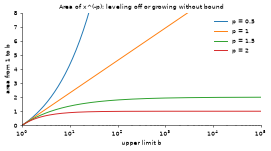

In [10]:
bs = np.array([1, 5, 10, 100, 1_000, 10_000, 100_000], dtype=float)
print("integral of e^(-x) from 0 to b:", np.round(1 - np.exp(-bs), 5))
print(f"\n{'b':>9} " + " ".join(f"p={p:<5}" for p in [0.5, 1, 1.5, 2]))
for b in bs[1:]:
    row = [(2 * np.sqrt(b) - 2), np.log(b), 2 - 2 / np.sqrt(b), 1 - 1 / b]    # exact integrals of x^(-p) on [1, b]
    print(f"{b:>9.0f} " + " ".join(f"{v:<7.3f}" for v in row))
print("limits for p = 1.5 and p = 2:", 1 / (1.5 - 1), 1 / (2 - 1))

bgrid = np.logspace(0, 5, 200)
fig, ax = plt.subplots(figsize=(6, 3.4))
for p, formula in [(0.5, lambda b: 2 * np.sqrt(b) - 2), (1, np.log), (1.5, lambda b: 2 - 2 / np.sqrt(b)), (2, lambda b: 1 - 1 / b)]:
    ax.plot(bgrid, formula(bgrid), label=f"p = {p}")
ax.set_xscale("log"); ax.set_ylim(0, 8); ax.set_xlim(1, 1e5); ax.set_xlabel("upper limit b"); ax.set_ylabel("area from 1 to b")
ax.set_title("Area of x^(-p): leveling off or growing without bound"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 8. Numerical rules and `quad`

Here are the midpoint, trapezoid, and Simpson rules from scratch, tested on $\int_0^1 e^x\,dx = e - 1$. On a log-log plot, an error proportional to $h^k$ is a straight line with slope $-k$ against $n$. The midpoint and trapezoid rules have slope $-2$ and Simpson's rule has slope $-4$, so it sinks much faster until it reaches rounding error.

midpoint   fitted slope of log(error) vs log(n): -2.00
trapezoid  fitted slope of log(error) vs log(n): -2.00
simpson    fitted slope of log(error) vs log(n): -3.99


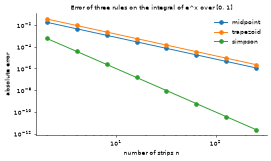

In [11]:
def midpoint(f, a, b, n):
    h = (b - a) / n
    return h * np.sum(f(a + h * (np.arange(n) + 0.5)))

def trapezoid_rule(f, a, b, n):
    pts = np.linspace(a, b, n + 1)
    return (b - a) / n * (f(pts).sum() - (f(a) + f(b)) / 2)

def simpson_rule(f, a, b, n):                          # n must be even
    pts = np.linspace(a, b, n + 1)
    return (b - a) / (3 * n) * (f(pts[0]) + 4 * f(pts[1:-1:2]).sum() + 2 * f(pts[2:-1:2]).sum() + f(pts[-1]))

ns = np.array([2, 4, 8, 16, 32, 64, 128, 256])
exact = np.e - 1
errs = {name: np.array([abs(rule(np.exp, 0, 1, n) - exact) for n in ns])
        for name, rule in [("midpoint", midpoint), ("trapezoid", trapezoid_rule), ("simpson", simpson_rule)]}
for name, e in errs.items():
    slope = np.polyfit(np.log(ns[:5]), np.log(e[:5]), 1)[0]
    print(f"{name:10} fitted slope of log(error) vs log(n): {slope:.2f}")

fig, ax = plt.subplots(figsize=(6, 3.6))
for name, e in errs.items():
    ax.loglog(ns, np.maximum(e, 1e-17), "o-", label=name)
ax.set_xlabel("number of strips n"); ax.set_ylabel("absolute error"); ax.set_title("Error of three rules on the integral of e^x over [0, 1]")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Library routines do this better. `quad` chooses its points adaptively and returns the value together with an estimate of its own error. It also accepts infinite limits, and `scipy.integrate.trapezoid` and `scipy.integrate.simpson` take sampled data.

In [12]:
from scipy.integrate import simpson
value, err_estimate = quad(np.exp, 0, 1)
print("quad:", value, "| error estimate:", err_estimate, "| close to e - 1:", np.isclose(value, exact))
xs_data = np.linspace(0, 1, 9)                         # 9 sampled points = 8 strips
print("trapezoid on samples:", trapezoid(np.exp(xs_data), xs_data), "| simpson on samples:", simpson(np.exp(xs_data), x=xs_data))
print("infinite range:", quad(lambda s: np.exp(-s), 0, np.inf)[0], "| 1/x^2 on [1, inf):", quad(lambda s: s**-2, 1, np.inf)[0])

quad: 1.7182818284590453 | error estimate: 1.9076760487502457e-14 | close to e - 1: True
trapezoid on samples: 1.7205185921643018 | simpson on samples: 1.7182841546998968
infinite range: 1.0000000000000002 | 1/x^2 on [1, inf): 1.0


## 9. The Gaussian integral

$e^{-x^2}$ has no antiderivative made of the usual functions (SymPy answers with the error function, `erf`), yet its total area is $\sqrt{\pi}$. Below, the area from $-b$ to $b$ climbs toward that number as $b$ grows, and it is already within rounding error of $\sqrt{\pi}$ for $b$ around 6. Dividing $e^{-x^2/2}$ by its total area $\sqrt{2\pi}$ gives the standard normal density, whose total area is exactly $1$.

SymPy antiderivative: sqrt(pi)*erf(x)/2
area from -1 to 1: 1.4936482656   (sqrt(pi) = 1.7724538509)
area from -2 to 2: 1.7641627815   (sqrt(pi) = 1.7724538509)
area from -3 to 3: 1.7724146965   (sqrt(pi) = 1.7724538509)
area from -4 to 4: 1.7724538236   (sqrt(pi) = 1.7724538509)
area from -6 to 6: 1.7724538509   (sqrt(pi) = 1.7724538509)
whole line: 1.7724538509055159 True
normal density total area: 0.9999999999999998 | without the factor: 2.5066282746309994 2.5066282746310002


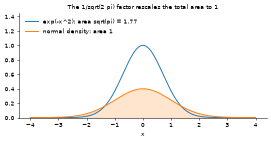

In [13]:
print("SymPy antiderivative:", sp.integrate(sp.exp(-x**2), x))
g = lambda s: np.exp(-s**2)
for b in [1, 2, 3, 4, 6]:
    print(f"area from -{b} to {b}: {quad(g, -b, b)[0]:.10f}   (sqrt(pi) = {np.sqrt(np.pi):.10f})")
total = quad(g, -np.inf, np.inf)[0]
print("whole line:", total, np.isclose(total, np.sqrt(np.pi)))

normal = lambda s: np.exp(-s**2 / 2) / np.sqrt(2 * np.pi)
print("normal density total area:", quad(normal, -np.inf, np.inf)[0], "| without the factor:", quad(lambda s: np.exp(-s**2 / 2), -np.inf, np.inf)[0], np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(6, 3.2))
s = np.linspace(-4, 4, 300)
ax.plot(s, g(s), label="exp(-x^2): area sqrt(pi) = 1.77")
ax.plot(s, normal(s), label="normal density: area 1")
ax.fill_between(s, normal(s), alpha=0.2, color="C1"); ax.set_ylim(0, 1.45); ax.legend(frameon=False, loc="upper left"); ax.set_xlabel("x")
ax.set_title("The 1/sqrt(2 pi) factor rescales the total area to 1")
plt.tight_layout(); plt.show()

## 10. A density, its CDF, and the expected value

A probability density $f$ is non-negative with total area $1$. Probabilities are areas under it, the CDF $F(x) = \int_{-\infty}^x f$ is an area function (so $F' = f$ by the fundamental theorem), and the expected value is $E[X] = \int x f(x)\,dx$. Two densities, both checked by hand in the README: $f(x) = 2x$ on $[0,1]$ and the exponential density $e^{-x}$ on $[0, \infty)$.

total area: 1.0 | E[X]: 0.6666666666666667 (exact 2/3)
P(X <= 0.5): 0.25 | P(X > 0.5): 0.75
CDF matches x^2: True | slope of CDF matches density: True

exponential density e^(-x): total 1.0000000000000002 | E[X]: 0.9999999999999998


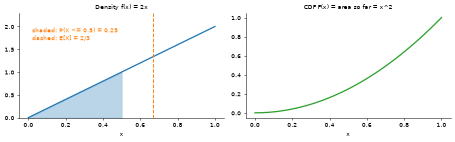

In [14]:
dens = lambda s: 2 * s                                 # density on [0, 1]
print("total area:", quad(dens, 0, 1)[0], "| E[X]:", quad(lambda s: s * dens(s), 0, 1)[0], "(exact 2/3)")
print("P(X <= 0.5):", quad(dens, 0, 0.5)[0], "| P(X > 0.5):", quad(dens, 0.5, 1)[0])
xs1 = np.linspace(0, 1, 201)
cdf = cumulative_trapezoid(dens(xs1), xs1, initial=0)   # area function
print("CDF matches x^2:", np.allclose(cdf, xs1**2), "| slope of CDF matches density:", np.allclose(np.gradient(cdf, xs1)[2:-2], dens(xs1)[2:-2], atol=1e-3))
print("\nexponential density e^(-x): total", quad(lambda s: np.exp(-s), 0, np.inf)[0], "| E[X]:", quad(lambda s: s * np.exp(-s), 0, np.inf)[0])

fig, (c1, c2) = plt.subplots(1, 2, figsize=(10, 3.2))
c1.plot(xs1, dens(xs1), "C0", lw=2); m = xs1 <= 0.5
c1.fill_between(xs1[m], dens(xs1)[m], color="C0", alpha=0.3); c1.axvline(2 / 3, color="C1", ls="--")
c1.text(0.02, 1.7, "shaded: P(X <= 0.5) = 0.25\ndashed: E[X] = 2/3", color="C1")
c1.set_xlabel("x"); c1.set_ylim(0, 2.3); c1.set_title("Density f(x) = 2x")
c2.plot(xs1, cdf, "C2", lw=2); c2.set_xlabel("x"); c2.set_title("CDF F(x) = area so far = x^2")
plt.tight_layout(); plt.show()

## 11. Softplus is an antiderivative of the sigmoid

The chain rule gives $\frac{d}{dx}\ln(1 + e^x) = \frac{e^x}{1 + e^x} = \sigma(x)$, so by the fundamental theorem the area under the sigmoid between two points is a difference of softplus values.

derivative of softplus equals sigmoid: True
area under sigmoid on [-5, 2]: 2.1202126625538544 | softplus(2) - softplus(-5): 2.1202126625538544
SymPy: exp(x)/(exp(x) + 1) | sigmoid derivative sigma(1 - sigma) at 0: 0.25


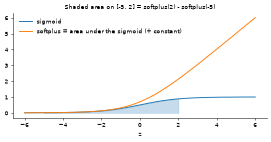

In [15]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
softplus = lambda z: np.log1p(np.exp(z))
zs = np.linspace(-6, 6, 1201)
print("derivative of softplus equals sigmoid:", np.allclose(np.gradient(softplus(zs), zs)[2:-2], sigmoid(zs)[2:-2], atol=1e-4))
print("area under sigmoid on [-5, 2]:", quad(sigmoid, -5, 2)[0], "| softplus(2) - softplus(-5):", softplus(2) - softplus(-5))
print("SymPy:", sp.simplify(sp.diff(sp.log(1 + sp.exp(x)), x)), "| sigmoid derivative sigma(1 - sigma) at 0:", sigmoid(0) * (1 - sigmoid(0)))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(zs, sigmoid(zs), label="sigmoid"); ax.plot(zs, softplus(zs), label="softplus = area under the sigmoid (+ constant)")
ax.fill_between(zs[(zs >= -5) & (zs <= 2)], sigmoid(zs[(zs >= -5) & (zs <= 2)]), alpha=0.25, color="C0")
ax.legend(frameon=False, loc="upper left"); ax.set_xlabel("z"); ax.set_title("Shaded area on [-5, 2] = softplus(2) - softplus(-5)")
plt.tight_layout(); plt.show()

## 12. Monte Carlo integration

Average $f$ at random points of $[a, b]$ and multiply by the length. For $\int_0^2 e^{-x^2}\,dx$ the exact value is $\frac{\sqrt\pi}{2}\,\mathrm{erf}(2)$. The error of one estimate is random, so we average the error over many repeats. It falls like $1/\sqrt{N}$, so the line on a log-log plot has slope $-\frac12$. The same method estimates $\pi$ as four times the area of a quarter circle.

fitted slope of log(error) vs log(N): -0.51 (theory: -0.5)
error * sqrt(N): [0.56 0.55 0.52 0.52 0.53 0.54 0.53]
pi estimate from 1,000,000 samples: 3.139893077777453 | true: 3.141592653589793


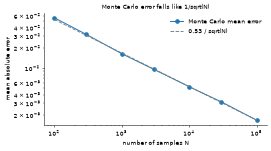

In [16]:
rng = np.random.default_rng(0)
f_mc = lambda s: np.exp(-s**2)
exact_mc = np.sqrt(np.pi) / 2 * erf(2)
Ns = np.array([100, 300, 1_000, 3_000, 10_000, 30_000, 100_000])
mean_err = np.array([np.mean([abs(2 * f_mc(rng.uniform(0, 2, N)).mean() - exact_mc) for _ in range(200)]) for N in Ns])
print("fitted slope of log(error) vs log(N):", round(np.polyfit(np.log(Ns), np.log(mean_err), 1)[0], 2), "(theory: -0.5)")
print("error * sqrt(N):", np.round(mean_err * np.sqrt(Ns), 2))
quarter = 4 * np.sqrt(1 - rng.uniform(0, 1, 1_000_000) ** 2).mean()
print("pi estimate from 1,000,000 samples:", quarter, "| true:", np.pi)

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.loglog(Ns, mean_err, "o-", label="Monte Carlo mean error")
ax.loglog(Ns, 0.53 / np.sqrt(Ns), "--", color="gray", label="0.53 / sqrt(N)")
ax.set_xlabel("number of samples N"); ax.set_ylabel("mean absolute error"); ax.legend(frameon=False)
ax.set_title("Monte Carlo error falls like 1/sqrt(N)")
plt.tight_layout(); plt.show()

## 13. AUC: the area under an ROC curve

A classifier's ROC curve plots the true positive rate against the false positive rate as the threshold moves. Its area (AUC) is computed with the trapezoid rule. First an invented curve given as points, then a synthetic experiment: scores for 300 invented positives and 300 invented negatives, an ROC curve built by sweeping the threshold, and a check that its trapezoid area equals the probability that a random positive outscores a random negative.

AUC of the invented curve: 0.8435000000000001
AUC by trapezoid: 0.7452 | pairwise probability: 0.7452 | equal: True


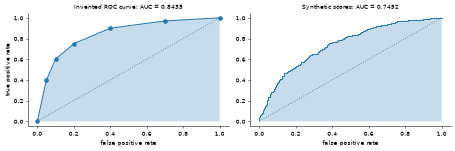

In [17]:
fpr = np.array([0.0, 0.05, 0.10, 0.20, 0.40, 0.70, 1.0])
tpr = np.array([0.0, 0.40, 0.60, 0.75, 0.90, 0.97, 1.0])
print("AUC of the invented curve:", trapezoid(tpr, fpr))

rng = np.random.default_rng(1)
pos = rng.normal(1.0, 1.0, 300)                        # invented scores of the positive class
neg = rng.normal(0.0, 1.0, 300)                        # invented scores of the negative class
scores = np.concatenate([pos, neg]); labels = np.concatenate([np.ones(300), np.zeros(300)])
order = np.argsort(-scores)                            # sweep the threshold from high to low
tpr2 = np.concatenate([[0], np.cumsum(labels[order]) / 300])
fpr2 = np.concatenate([[0], np.cumsum(1 - labels[order]) / 300])
auc = trapezoid(tpr2, fpr2)
pairwise = np.mean(pos[:, None] > neg[None, :])        # P(random positive outscores random negative)
print("AUC by trapezoid:", round(auc, 4), "| pairwise probability:", round(pairwise, 4), "| equal:", np.isclose(auc, pairwise))

fig, (d1, d2) = plt.subplots(1, 2, figsize=(10, 3.4))
d1.plot(fpr, tpr, "o-"); d1.fill_between(fpr, tpr, alpha=0.25); d1.plot([0, 1], [0, 1], ":", color="gray")
d1.set_title(f"Invented ROC curve: AUC = {trapezoid(tpr, fpr):.4f}"); d1.set_xlabel("false positive rate"); d1.set_ylabel("true positive rate")
d2.plot(fpr2, tpr2); d2.fill_between(fpr2, tpr2, alpha=0.25); d2.plot([0, 1], [0, 1], ":", color="gray")
d2.set_title(f"Synthetic scores: AUC = {auc:.4f}"); d2.set_xlabel("false positive rate")
plt.tight_layout(); plt.show()

## Summary

- The definite integral is the limit of Riemann sums, a signed area that is linear and splits over intervals. Left sums sit below and right sums above for a rising function, with the midpoint sum closest.
- The fundamental theorem links area and slope: the area function has derivative $f$, and $\int_a^b f = F(b) - F(a)$. SymPy finds antiderivatives, and substitution and by parts are checked by differentiating the result.
- Areas between curves, average values, disc volumes, and totals from rates all come from the same integral. Improper integrals are limits, and $\int_1^\infty x^{-p}$ converges only for $p > 1$.
- Midpoint and trapezoid errors fall like $1/n^2$, Simpson's like $1/n^4$, and `quad` adapts. The Gaussian integral has no formula antiderivative and total area $\sqrt\pi$.
- In AI: a density has area $1$, the CDF is an area function, softplus integrates the sigmoid, Monte Carlo error falls like $1/\sqrt{N}$, and AUC is a trapezoid-rule area.

Next, [Multivariable Calculus](../multivariable-calculus/README.md) moves from one variable to many: partial derivatives, gradients, and double integrals.